# Arc and Distance Calculations

## Imports

In [6]:
# Import standard data prep and eda libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd



## Data Mapping for Eventual Distance Calculations

| Feature | Role | Source file | Status |
|---|---|---|---|
| Hatcheries | Supply | `trout_hatcheries.gpkg` | Processed data folder |
| Coop Nurseries | Supply | `coop_nurseries.geojson` | Raw Data |
| Class A Streams | Demand | `pa_class_a_trout_streams.gpkg` | Raw Data |
| Stocked Trout Streams | Demand | `pa_stocked_trout_streams.gpkg` | Raw data |
| Roads | Arc | TBD | WIP |


## Goal: Matrix of distance from Hatchery/Coop to Stream, using roads as arc


In [ ]:
CRS_M = 5070          # CONUS Albers, meters
N_NEAREST = 2


# Import hatcheries, coop nurseries, class a streams, stocked trout streams
hatcheries = gpd.read_file("../data/processed/trout_hatcheries.gpkg").to_crs(CRS_M)
coop_nurseries = gpd.read_file("../data/raw/Coop_nurseries.geojson").to_crs(CRS_M)
class_a = gpd.read_file("../data/raw/pa_class_a_trout_streams.gpkg").to_crs(CRS_M)
stocked_trout = gpd.read_file("../data/raw/pa_stocked_trout_streams.gpkg")
pa_boundary = gpd.read_file("../data/raw/pa_boundary.gpkg")

### Plot Nodes

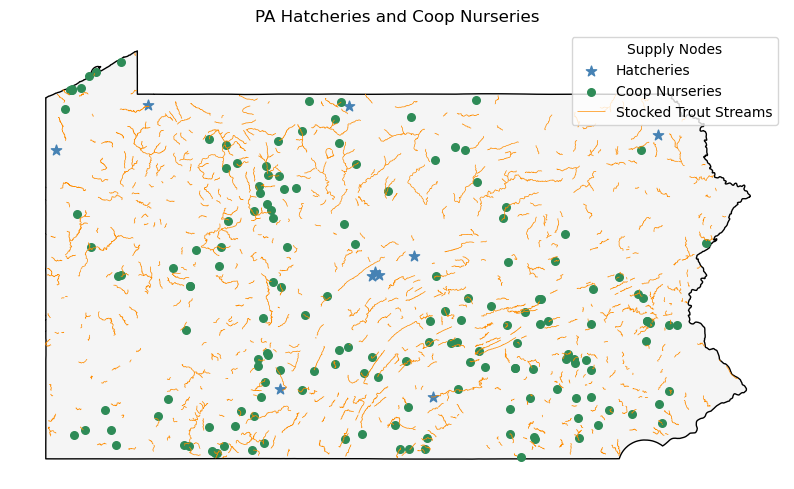

In [34]:
# Show hatcheries and coop nurseries on the map with distinct symbols.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

hatcheries.plot(
    ax=ax,
    marker="*",
    color="steelblue",
    markersize=60,
    label="Hatcheries",
)
coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=30,
    label="Coop Nurseries",
)


stocked_trout.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Streams",
)

ax.set_title("PA Hatcheries and Coop Nurseries")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
plt.show()

## Calculate Distance from Supply Node to Demand Node, using Roads as Arcs

### Coop Nurseries to Stocked Steams - Closest 2 streams

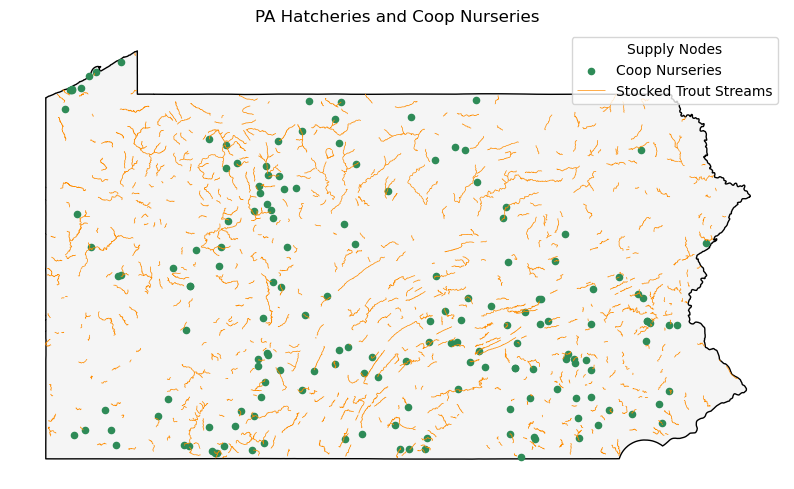

In [36]:
# Show hatcheries and coop nurseries on the map with distinct symbols.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=20,
    label="Coop Nurseries",
)


stocked_trout.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Streams",
)

ax.set_title("PA Hatcheries and Coop Nurseries")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
plt.show()

In [ ]:

#For each coop, find the N closest *distinct* streams
rows = []
for h in coop.itertuples():
    d = streams.distance(h.geometry)                       # meters, to nearest point on each line
    near = (streams.assign(dist_m=d)
                   .sort_values("dist_m")
                   .drop_duplicates("RFP_WaterID")         # one row per stream, not per section
                   .head(N_NEAREST))
    for rank, s in enumerate(near.itertuples(), start=1):
        rows.append({
            "hatchery": h.NAME,
            "rank": rank,
            "stream": s.GNIS_Name,
            "rfp_water_id": s.RFP_WaterID,
            "dist_km": round(s.dist_m / 1000, 2),
        })

result = pd.DataFrame(rows)
result.to_csv("data/interim/hatchery_nearest_streams.csv", index=False)